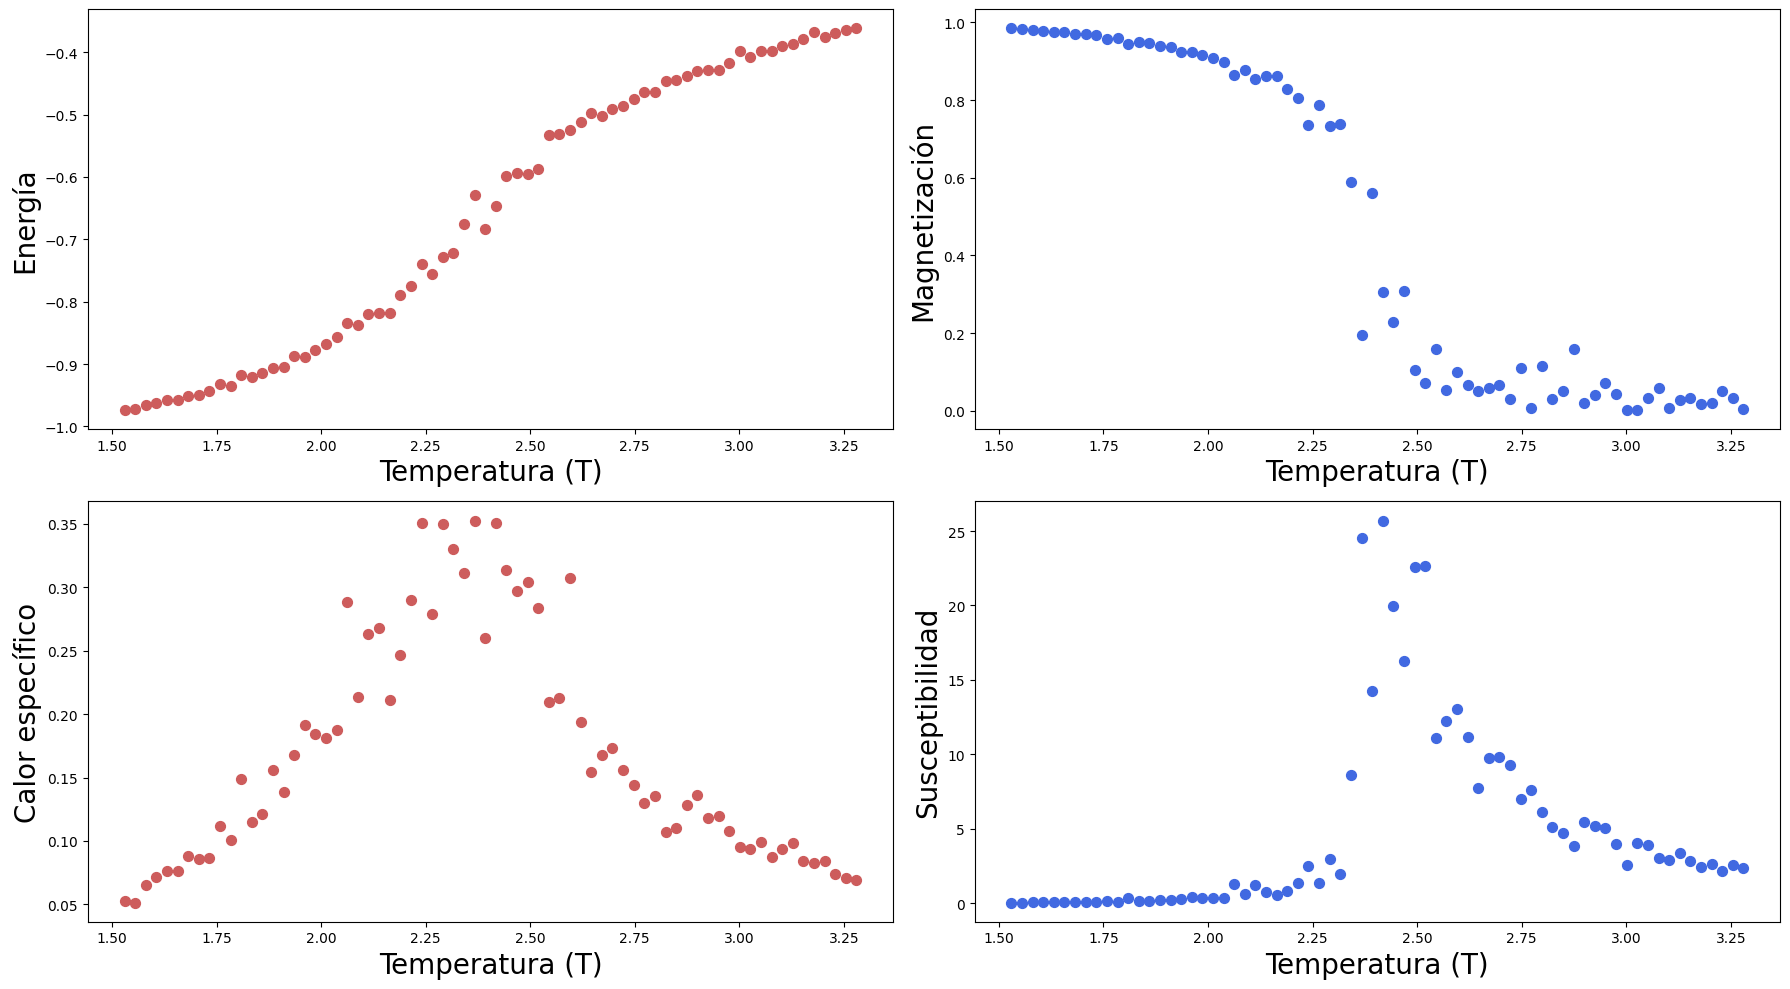

In [ ]:
%matplotlib inline
from __future__ import division
import numpy as np
from numpy.random import rand
import matplotlib.pyplot as plt

#----------------------------------------------------------------------
## BLOQUE DE FUNCIONES UTILIZADAS EN EL CÓDIGO PRINCIPAL
#----------------------------------------------------------------------
def initialstate(N):
    ''' genera una configuración de giro aleatoria para la condición inicial'''
    state = 2 *np.random.randint(2, size=(N,N)) - 1
    return state

def mcmove(config, beta):
    ''' Movimiento de Monte Carlo utilizando el algoritmo de Metropolis '''
    # N es una variable global (N=16)
    for i in range(N):
        for j in range(N):
            a = np.random.randint(0, N)
            b = np.random.randint(0, N)
            s = config[a, b]
            # Condiciones de frontera periódicas
            nb = config[(a+1)%N, b] + config[a,(b+1)%N] + config[(a-1)%N, b] + config[a,(b-1)%N]
            cost = 2 * s * nb

            # Regla de Metropolis
            if cost < 0:
                s *= -1
            elif rand() < np.exp(-cost * beta):
                s *= -1

            config[a, b] = s
    return config

def calcEnergy(config):
    '''Energía de una configuración dada'''
    energy = 0
    for i in range(len(config)):
        for j in range(len(config)):
            S = config[i,j]
            # Condiciones de frontera periódicas
            nb = config[(i+1)%N, j] + config[i,(j+1)%N] + config[(i-1)%N, j] + config[i,(j-1)%N]
            energy += -nb*S
    return energy / 4.

def calcMag(config):
    '''Magnetización de una configuración dada'''
    mag = np.sum(config)
    return mag

#----------------------------------------------------------------------
## PARÁMETROS PRINCIPALES Y BUCLE DE SIMULACIÓN
#----------------------------------------------------------------------
# Cambie estos parámetros para una simulación más pequeña (y rápida)
nt = 70          # número de puntos de temperatura
N = 14          # tamaño de la red, N x N
eqSteps = 1024        # número de barridos MC para la equilibración
mcSteps = 1024        # número de barridos MC para el cálculo

T = np.linspace(1.53, 3.28, nt)
E, M, C, X = np.zeros(nt), np.zeros(nt), np.zeros(nt), np.zeros(nt)
n1, n2 = 1.0 / (mcSteps * N * N), 1.0 / (mcSteps * mcSteps * N * N)
# divida por el número de muestras y por el tamaño del sistema para obtener valores intensivos

# PARTE PRINCIPAL DEL CÓDIGO
for tt in range(nt):
    E1 = M1 = E2 = M2 = 0
    config = initialstate(N) # Corregido: 'estadoInicial' -> 'initialstate'
    iT = 1.0 / T[tt]
    iT2 = iT * iT

    # equilibrar
    for i in range(eqSteps): # Corregido: 'pasosEq' -> 'eqSteps'
        mcmove(config, iT)

    # calcular
    for i in range(mcSteps): # Corregido: 'pasosMc' -> 'mcSteps'
        mcmove(config, iT)
        Ene = calcEnergy(config)
        Mag = calcMag(config)

        E1 = E1 + Ene
        M1 = M1 + Mag
        M2 = M2 + Mag * Mag
        E2 = E2 + Ene * Ene

    # Calcular valores promedio
    E[tt] = n1 * E1
    M[tt] = n1 * M1

    # Calcular Calor Específico (C) y Susceptibilidad (X)
    C[tt] = (n1 * E2 - n2 * E1 * E1) * iT2
    X[tt] = (n1 * M2 - n2 * M1 * M1) * iT

# Graficar los valores calculados
f = plt.figure(figsize=(18, 10))

# Subplot 1: Energía
sp = f.add_subplot(2, 2, 1)
plt.scatter(T, E, s=50, marker='o', color='IndianRed')
plt.xlabel("Temperatura (T)", fontsize=20)
plt.ylabel("Energía", fontsize=20)
plt.axis('tight')

# Subplot 2: Magnetización
sp = f.add_subplot(2, 2, 2)
plt.scatter(T, abs(M), s=50, marker='o', color='RoyalBlue')
plt.xlabel("Temperatura (T)", fontsize=20)
plt.ylabel("Magnetización", fontsize=20)
plt.axis('tight')

# Subplot 3: Calor Específico
sp = f.add_subplot(2, 2, 3)
plt.scatter(T, C, s=50, marker='o', color='IndianRed')
plt.xlabel("Temperatura (T)", fontsize=20)
plt.ylabel("Calor específico", fontsize=20)
plt.axis('tight')

# Subplot 4: Susceptibilidad
sp = f.add_subplot(2, 2, 4)
plt.scatter(T, X, s=50, marker='o', color='RoyalBlue')
plt.xlabel("Temperatura (T)", fontsize=20)
plt.ylabel("Susceptibilidad", fontsize=20)
plt.axis('tight')

plt.tight_layout()
plt.show()

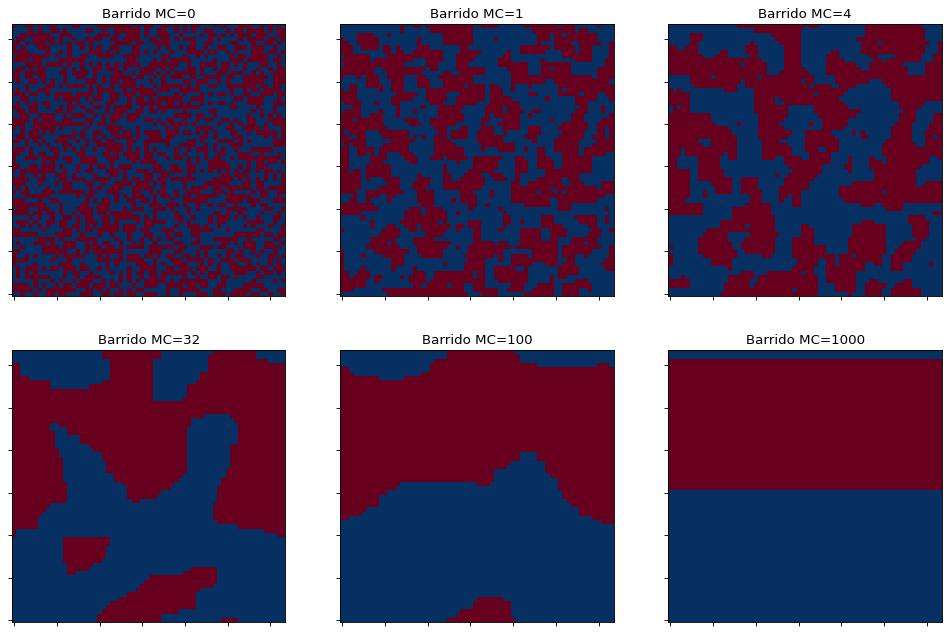

In [ ]:
%matplotlib inline
# Simulación del modelo de Ising
from __future__ import division
import numpy as np
from numpy.random import rand
import matplotlib.pyplot as plt

class Ising():
    ''' Simulación del modelo de Ising '''
    ## movimientos de Monte Carlo
    def mcmove(self, config, N, beta):
        ''' Esto ejecuta los movimientos de Monte Carlo utilizando
        el algoritmo de Metropolis de manera que
        se satisfaga la condición de balance detallado'''
        for i in range(N):
            for j in range(N):
                    a = np.random.randint(0, N)
                    b = np.random.randint(0, N)
                    s = config[a, b]
                    # Vecinos más cercanos (Periodic Boundary Conditions)
                    nb = config[(a+1)%N,b] + config[a,(b+1)%N] + config[(a-1)%N,b] + config[a,(b-1)%N]
                    cost = 2 * s * nb # Cambio de energía

                    # Regla de Metropolis
                    if cost < 0: # Corregido: 'si costo' -> 'if cost'
                        s *= -1
                    elif rand() < np.exp(-cost * beta): # Corregido: 'costo' -> 'cost'
                        s *= -1
                    config[a, b] = s
        return config

    def simulate(self):
        ''' Este módulo simula el modelo de Ising'''
        # Parámetros: N=64 (red 64x64), temp=0.4 (muy baja, ferromagnética)
        N, temp = 64, .4         # Inicializar la red
        config = 2 *np.random.randint(2, size=(N,N)) - 1 # Configuración inicial aleatoria

        f = plt.figure(figsize=(15, 15), dpi=80)
        self.configPlot(f, config, 0, N, 1) # Plot en tiempo t=0

        msrmnt = 1001
        for i in range(msrmnt):
            # Realizar un barrido de Monte Carlo (N*N intentos de flip)
            self.mcmove(config, N, 1.0 / temp)

            # Graficar la configuración en tiempos específicos (i = número de barridos MC)
            if i == 1: self.configPlot(f, config, i, N, 2)
            if i == 4: self.configPlot(f, config, i, N, 3) # Corregido 'Si i == 4'
            if i == 32: self.configPlot(f, config, i, N, 4) # Corregido 'si i == 32'
            if i == 100: self.configPlot(f, config, i, N, 5)
            if i == 1000: self.configPlot(f, config, i, N, 6)

    def configPlot(self, f, config, i, N, n_):
        ''' Este módulo grafica la configuración una vez que se le pasa, junto con el tiempo, etc. '''
        X, Y = np.meshgrid(range(N), range(N))
        sp = f.add_subplot(3, 3, n_)
        plt.setp(sp.get_yticklabels(), visible=False)
        plt.setp(sp.get_xticklabels(), visible=False)
        plt.pcolormesh(X, Y, config, cmap=plt.cm.RdBu)
        plt.title('Barrido MC=%d'%i) # Corregido 'Hora' a 'Tiempo' en el plot
        plt.axis('tight')

    def run(self):
        self.simulate()

# Ejecutar la simulación
rm = Ising()
rm.run()
plt.show() # Asegurar que se muestren todos los plots

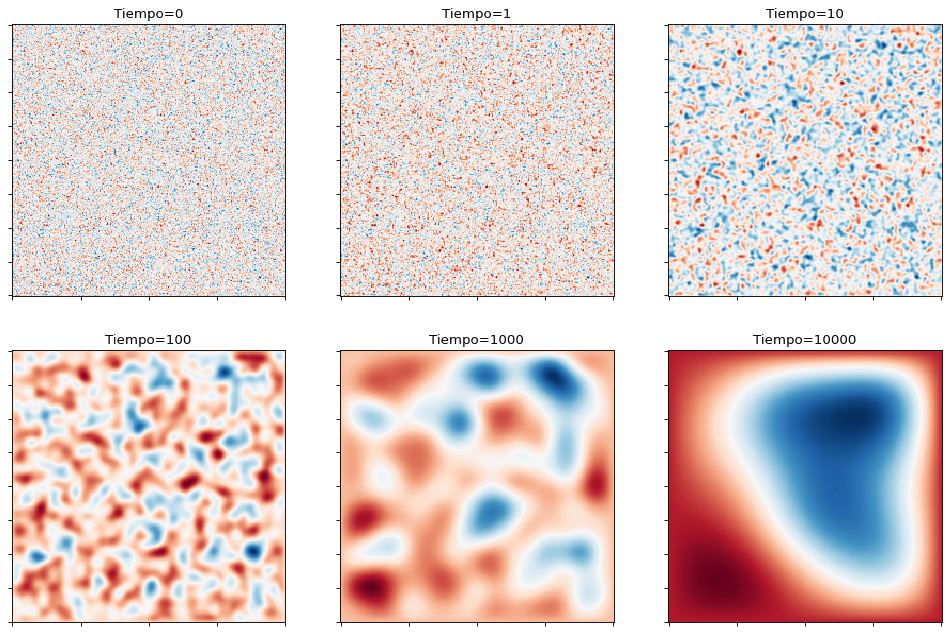

In [ ]:
# Simulación de la ecuación TDGL

%matplotlib inline
import numpy as np
from __future__ import division
from scipy.sparse import spdiags, linalg, eye
import matplotlib.pyplot as plt


# Parámetros de la ecuación
a, b, k = 1.0, 1.0, 100.0
# Parámetros de discretización
dh, dt = 1.0, 1e-3
# Tamaño de la red (Ng x Ng) y pasos de tiempo
Ng, Tf = 256, 10001

class TDGL():
    '''
    Clase para resolver la Ecuación de Ginzburg-Landau Dependiente del Tiempo (TDGL)
    '''
    def mu(self, u):
        # Término no lineal (derivada del potencial de energía libre)
        return a * u + b * u * u * u

    def laplacian(self, Ng):
        '''Construye una matriz dispersa que aplica la discretización laplaciana de 5 puntos'''
        e = np.ones(Ng**2)
        # Coeficientes para las diagonales:
        # e2: [1] para conexiones horizontales (izq)
        e2 = ([1]*(Ng - 1) + [0]) * Ng
        # e3: [1] para conexiones horizontales (der)
        e3 = ([0] + [1]*(Ng - 1)) * Ng
        h = dh

        # spdiags: (datos, offsets, forma)
        # Offsets: 0 (central), -1, 1 (vecinos horizontales), -Ng, Ng (vecinos verticales)
        A = spdiags([-4 * e, e2, e3, e, e], [0, -1, 1, -Ng, Ng], Ng**2, Ng**2)
        A /= h**2
        return A

    def integrate(self, L, x, y, u):
        ''' simula la ecuación y la grafica en diferentes instantes '''
        f = plt.figure(figsize=(15, 15), dpi=80)

        for i in range(Tf):
            # Método de Euler explícito para la integración en el tiempo
            u = u - dt * (self.mu(u) - k * L.dot(u))

            # Graficar la configuración en instantes específicos
            if i == 0: self.configPlot(x, y, u, f, 1, i)
            if i == 1: self.configPlot(x, y, u, f, 2, i) # Corregido 'Si'
            if i == 10: self.configPlot(x, y, u, f, 3, i) # Corregido 'si'
            if i == 100: self.configPlot(x, y, u, f, 4, i) # Corregido 'si'
            if i == 1000: self.configPlot(x, y, u, f, 5, i) # Corregido 'si'
            if i == 10000: self.configPlot(x, y, u, f, 6, i) # Corregido 'si'

    def configPlot(self, x, y, u, f, n_, i):
        U = u.reshape((Ng, Ng))
        sp = f.add_subplot(3, 3, n_)
        plt.setp(sp.get_yticklabels(), visible=False)
        plt.setp(sp.get_xticklabels(), visible=False)
        plt.pcolormesh(x, y, U, cmap=plt.cm.RdBu)
        plt.title('Tiempo=%d' % i) # Corregido etiqueta 'Hora' a 'Tiempo'
        plt.axis('tight')

    # Método para iniciar la simulación
    def run(self):
        # Generar la malla e inicializar el campo
        x = np.linspace(-1, 1, Ng)
        y = np.linspace(-1, 1, Ng)
        X, Y = np.meshgrid(x, y)

        u = np.random.randn(Ng * Ng, 1) # Datos iniciales (ruido aleatorio)
        L = self.laplacian(Ng)          # Construir el laplaciano
        self.integrate(L, x, y, u)      # Simular

# Instanciar y ejecutar
rm = TDGL()
rm.run()
plt.show() # Mostrar todas las gráficas generadas

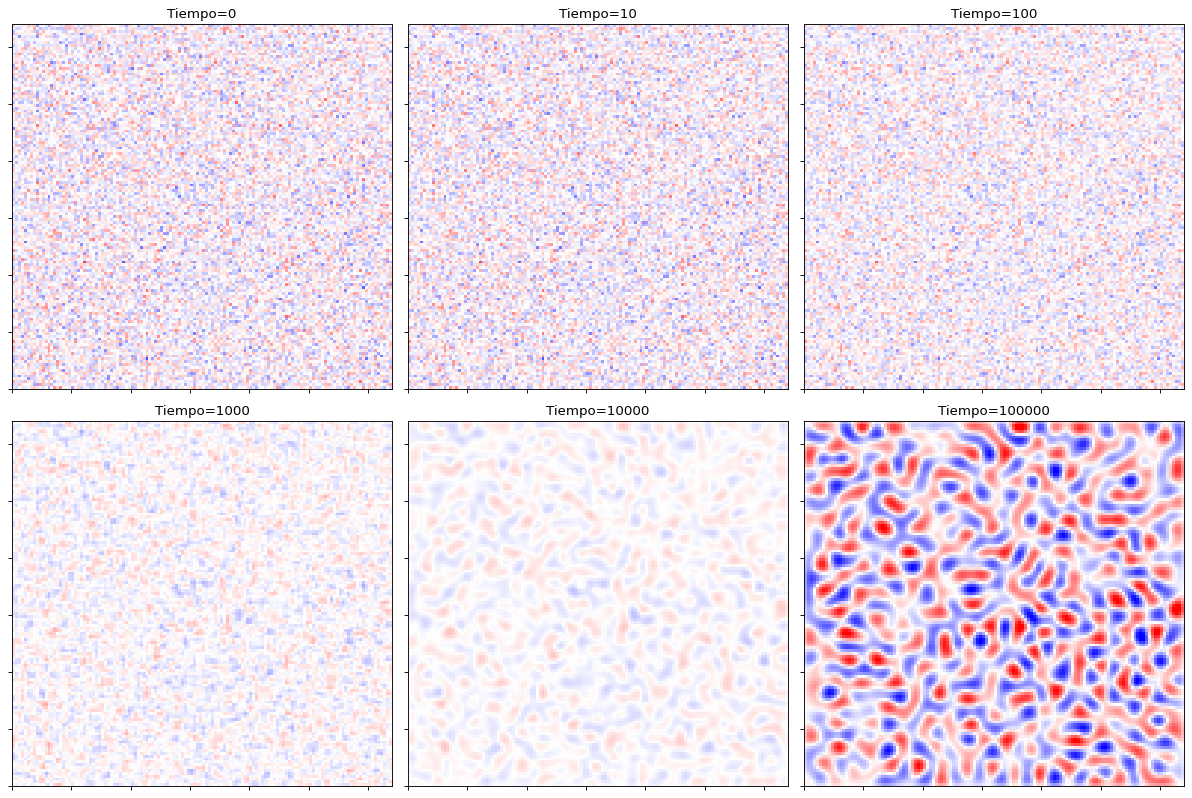

In [ ]:
%matplotlib inline
import numpy as np
from __future__ import division
from scipy.sparse import spdiags # Para matrices dispersas
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors # Necesario si definimos un cmap custom, pero no con 'bwr'

# --- PARÁMETROS DEL MODELO ---
M = 1.0 # Módulo de movilidad
kappa = 1.0 # Coeficiente de gradiente (energía de interfaz)

# --- PARÁMETROS DE DISCRETIZACIÓN AJUSTADOS ---
dt = 1e-4   # Paso de tiempo
Ng = 128    # Tamaño de la red (128 x 128)
Tf = 100001 # Número total de pasos de tiempo

class CahnHilliard():
    '''
    Clase para resolver la Ecuación de Cahn-Hilliard para Separación de Fases.
    '''

    def free_energy_deriv(self, u):
        # Derivada del potencial de energía libre (fuerza impulsora)
        return u * u * u - u

    def laplacian_matrix(self, Ng):
        '''Construye la matriz dispersa para el operador Laplaciano de 5 puntos.'''
        N_total = Ng**2
        e = np.ones(N_total)

        e2 = ([1]*(Ng - 1) + [0]) * Ng
        e3 = ([0] + [1]*(Ng - 1)) * Ng

        A = spdiags([-4 * e, e2, e3, e, e], [0, -1, 1, -Ng, Ng], N_total, N_total)
        return A

    def integrate(self, L, u):
        ''' Simula la ecuación de Cahn-Hilliard '''
        f = plt.figure(figsize=(15, 15), dpi=80)

        sampling_times = [0, 10, 100, 1000, 10000, 100000]

        for i in range(Tf):
            mu_bulk = self.free_energy_deriv(u)
            mu = mu_bulk - kappa * L.dot(u)

            u = u + dt * M * L.dot(mu)

            if i in sampling_times:
                n_ = sampling_times.index(i) + 1
                self.configPlot(u, f, n_, i)

        plt.tight_layout()
        plt.show()

    def configPlot(self, u, f, n_, i):
        U = u.reshape((Ng, Ng))
        sp = f.add_subplot(3, 3, n_)
        plt.setp(sp.get_yticklabels(), visible=False)
        plt.setp(sp.get_xticklabels(), visible=False)

        # --- CAMBIO AQUÍ: Usamos 'bwr' que es más contrastado ---
        cmap = plt.cm.bwr

        # Aseguramos que el rango de colores vaya de -1 a 1
        plt.pcolormesh(U, cmap=cmap, vmin=-0.3, vmax=0.3);
        plt.title('Tiempo=%d' % i)
        plt.axis('tight')

# --- INICIALIZACIÓN Y EJECUCIÓN ---

rm = CahnHilliard()
L = rm.laplacian_matrix(Ng)

u = 0.0 + 0.05 * np.random.randn(Ng * Ng)
u = u.reshape((Ng * Ng, 1))

rm.integrate(L, u)